# Lab 2 report



## LAB_INSTRUCTION.md

In `notebook_01_psycopg.ipynb`, I set up PostgreSQL, created the `services` table, and practiced querying it with Psycopg. I also added a query that exports Amsterdam Central trains with late arrivals and departures to JSONL; it returned no rows because the table had no matching data, then I copied the rows with psql command to the services table to postgres container. As the result 29396 rows were saved to data/late_train.jsonl

The `notebook_01_psycopg.ipynb` exercise was considerably more challenging than I expected. I spent around 2-3 hours troubleshooting table-creation and query errors, and checking that the data was loaded correctly before running queries.


# HOMEWORK.md

## Step 1: Download the datasets


In [1]:
from pathlib import Path
from urllib.request import urlretrieve

DATA_DIR = Path("data")
DATA_DIR.mkdir(exist_ok=True)

download_items = {
    "stations-2023-09.csv": "https://opendata.rijdendetreinen.nl/public/stations/stations-2023-09.csv",
    "tariff-distances-2022-01.csv": "https://blobs.duckdb.org/data/tariff-distances-2022-01.csv",
}
download_items.update({
    f"disruptions-{year}.csv": f"https://opendata.rijdendetreinen.nl/public/disruptions/disruptions-{year}.csv"
    for year in range(2011, 2024)
})
download_items.update({
    f"services-{year}.csv.gz": f"https://opendata.rijdendetreinen.nl/public/services/services-{year}.csv.gz"
    for year in range(2019, 2026)
})

for filename, url in download_items.items():
    path = DATA_DIR / filename
    if path.is_file() and path.stat().st_size > 0:
        print(f"Already downloaded: {filename}")
        continue
    print(f"Downloading {filename}...")
    urlretrieve(url, path)
    print(f"Saved to {path}")

Already downloaded: stations-2023-09.csv
Already downloaded: tariff-distances-2022-01.csv
Already downloaded: disruptions-2011.csv
Already downloaded: disruptions-2012.csv
Already downloaded: disruptions-2013.csv
Already downloaded: disruptions-2014.csv
Already downloaded: disruptions-2015.csv
Already downloaded: disruptions-2016.csv
Already downloaded: disruptions-2017.csv
Already downloaded: disruptions-2018.csv
Already downloaded: disruptions-2019.csv
Already downloaded: disruptions-2020.csv
Already downloaded: disruptions-2021.csv
Already downloaded: disruptions-2022.csv
Already downloaded: disruptions-2023.csv
Already downloaded: services-2019.csv.gz
Already downloaded: services-2020.csv.gz
Already downloaded: services-2021.csv.gz
Already downloaded: services-2022.csv.gz
Already downloaded: services-2023.csv.gz
Already downloaded: services-2024.csv.gz
Already downloaded: services-2025.csv.gz


## Step 2: Load stations into DuckDB

In [2]:
import duckdb

db = duckdb.connect("data/homework.duckdb")
db.execute("""
CREATE OR REPLACE TABLE stations AS
SELECT *
FROM read_csv_auto('data/stations-2023-09.csv', header = true)
""")

display(db.sql("DESCRIBE stations").df())
display(db.sql("SELECT COUNT(*) AS station_count FROM stations").df())

,column_name,column_type,null,key,default,extra
0,id,BIGINT,YES,None,None,None
1,code,VARCHAR,YES,None,None,None
2,uic,BIGINT,YES,None,None,None
3,name_short,VARCHAR,YES,None,None,None
4,name_medium,VARCHAR,YES,None,None,None
5,name_long,VARCHAR,YES,None,None,None
6,slug,VARCHAR,YES,None,None,None
7,country,VARCHAR,YES,None,None,None
8,type,VARCHAR,YES,None,None,None
9,geo_lat,DOUBLE,YES,None,None,None


,station_count
0,591


## Step 3: Create the distance tables


In [3]:
db.execute("""
CREATE OR REPLACE TABLE distances AS
SELECT *
FROM read_csv('data/tariff-distances-2022-01.csv', header = true, nullstr = 'XXX')
""")

db.execute("""
CREATE OR REPLACE TABLE distances_long AS
UNPIVOT distances
ON COLUMNS (* EXCLUDE Station)
INTO NAME other_station VALUE distance
""")

display(db.sql("DESCRIBE distances").df().head())
display(db.sql("SELECT * FROM distances_long LIMIT 5").df())
display(db.sql("SELECT COUNT(*) AS station_rows FROM distances").df())
display(db.sql("SELECT COUNT(*) AS pair_rows FROM distances_long").df())

,column_name,column_type,null,key,default,extra
0,Station,VARCHAR,YES,None,None,None
1,AC,BIGINT,YES,None,None,None
2,AH,BIGINT,YES,None,None,None
3,AHP,BIGINT,YES,None,None,None
4,AHPR,BIGINT,YES,None,None,None


,Station,other_station,distance
0,AC,AH,82
1,AC,AHP,83
2,AC,AHPR,85
3,AC,AHZ,90
4,AC,AKL,71


,station_rows
0,399


,pair_rows
0,158802


## Step 4: Load disruptions into Postgres


In [4]:
import json
import subprocess

import psycopg
from psycopg import sql

compose_config = json.loads(subprocess.run(
    ["docker", "compose", "config", "--format", "json"],
    check=True,
    capture_output=True,
    text=True,
).stdout)
postgres_service = compose_config["services"]["postgres"]
postgres_env = postgres_service["environment"]
postgres_port = next(
    int(port["published"])
    for port in postgres_service["ports"]
    if int(port["target"]) == 5432
)
admin_conninfo = psycopg.conninfo.make_conninfo(
    host="localhost",
    port=postgres_port,
    user=postgres_env["POSTGRES_USER"],
    password=postgres_env["POSTGRES_PASSWORD"],
    dbname=postgres_env["POSTGRES_DB"],
)
homework_db_name = "lab02_homework"

with psycopg.connect(admin_conninfo, autocommit=True) as conn:
    with conn.cursor() as cur:
        cur.execute("SELECT 1 FROM pg_database WHERE datname = %s", (homework_db_name,))
        if cur.fetchone() is None:
            cur.execute(sql.SQL("CREATE DATABASE {}").format(sql.Identifier(homework_db_name)))

homework_conninfo = psycopg.conninfo.make_conninfo(admin_conninfo, dbname=homework_db_name)
disruption_files = [DATA_DIR / f"disruptions-{year}.csv" for year in range(2011, 2024)]
missing_files = [path for path in disruption_files if not path.is_file()]
if missing_files:
    raise FileNotFoundError(f"Missing disruption files: {missing_files}")

with psycopg.connect(homework_conninfo) as conn:
    with conn.cursor() as cur:
        cur.execute("""
            CREATE TABLE IF NOT EXISTS disruptions (
                rdt_id BIGINT,
                ns_lines TEXT,
                rdt_lines TEXT,
                rdt_lines_id TEXT,
                rdt_station_names TEXT,
                rdt_station_codes TEXT,
                cause_nl TEXT,
                cause_en TEXT,
                statistical_cause_nl TEXT,
                statistical_cause_en TEXT,
                cause_group TEXT,
                start_time TIMESTAMP,
                end_time TIMESTAMP,
                duration_minutes INTEGER
            )
        """)
        cur.execute("TRUNCATE TABLE disruptions")
        copy_sql = """
            COPY disruptions (
                rdt_id, ns_lines, rdt_lines, rdt_lines_id, rdt_station_names,
                rdt_station_codes, cause_nl, cause_en, statistical_cause_nl,
                statistical_cause_en, cause_group, start_time, end_time,
                duration_minutes
            ) FROM STDIN WITH (FORMAT CSV, HEADER TRUE)
        """
        with cur.copy(copy_sql) as copy:
            for file_index, path in enumerate(disruption_files):
                with path.open("rb") as source:
                    if file_index:
                        source.readline()  # Each annual CSV has the same header.
                    while chunk := source.read(1024 * 1024):
                        copy.write(chunk)

with psycopg.connect(homework_conninfo) as conn:
    with conn.cursor() as cur:
        cur.execute("SELECT COUNT(*) FROM disruptions")
        print(f"Loaded {cur.fetchone()[0]:,} disruptions into {homework_db_name}.disruptions")

Loaded 49,900 disruptions into lab02_homework.disruptions


## Step 5: Combine train services into Parquet

In [5]:
service_files = sorted(DATA_DIR.glob("services-*.csv.gz"))
if not service_files:
    raise FileNotFoundError("No annual services-*.csv.gz files found in data/")

services_parquet = DATA_DIR / "services.parquet"
if not services_parquet.is_file() or services_parquet.stat().st_size == 0:
    service_file_list = ", ".join(
        "'" + path.as_posix().replace("'", "''") + "'" for path in service_files
    )
    db.execute(f"""
        COPY (
            SELECT *
            FROM read_csv(
                [{service_file_list}],
                header = true,
                auto_detect = true,
                union_by_name = true
            )
        ) TO '{services_parquet.as_posix()}'
        (FORMAT PARQUET, COMPRESSION ZSTD)
    """)
else:
    print(f"Reusing existing {services_parquet}")

db.execute("""
    CREATE OR REPLACE TABLE services AS
    SELECT * FROM read_parquet('data/services.parquet')
""")
display(db.sql("SELECT COUNT(*) AS service_stop_rows FROM services").df())
print(f"Parquet size: {services_parquet.stat().st_size / (1024 ** 2):,.1f} MiB")

Reusing existing data\services.parquet


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,service_stop_rows
0,152176324


Parquet size: 1,044.1 MiB


## Step 6: Tables used for the analysis

The questions below use `services`, `distances_long`, `stations`, and the Postgres `disruptions` table in `lab02_homework`. Each row in `services` describes one train's stop, not an entire end-to-end journey: rows sharing `Service:RDT-ID` belong to the same service. The first stop has a NULL `Stop:Arrival time`, while the final stop has a NULL `Stop:Departure time`. Join station data using station codes; use `homework_conninfo` to query Postgres disruptions.


## Step 7: Analyze the data

The queries count distinct `Service:RDT-ID` values when asking about services, so a service with multiple stops is counted once. The services data has no explicit disruption ID; for question 8, a service is considered disrupted if it had a positive maximum delay or was partly or completely cancelled. The most common disruption cause is grouped by the year the disruption started.


In [6]:
import pandas as pd

# 1. Distinct train services that departed Amsterdam Centraal (ASD).
amsterdam_central_departures = db.sql("""
    SELECT COUNT(DISTINCT "Service:RDT-ID") AS departed_services
    FROM services
    WHERE "Stop:Station code" = 'ASD'
      AND "Stop:Departure time" IS NOT NULL
""").df()

# 2. Average arrival delay by train type, in minutes.
average_delay_by_type = db.sql("""
    SELECT "Service:Type" AS service_type,
           AVG("Stop:Arrival delay") AS average_arrival_delay_minutes
    FROM services
    WHERE "Stop:Arrival delay" IS NOT NULL
    GROUP BY "Service:Type"
    ORDER BY average_arrival_delay_minutes DESC
""").df()

# 3. Most common statistical cause by the year each disruption started.
with psycopg.connect(homework_conninfo) as conn:
    with conn.cursor() as cur:
        cur.execute("""
            SELECT EXTRACT(YEAR FROM start_time)::INTEGER AS year,
                   MODE() WITHIN GROUP (ORDER BY statistical_cause_en) AS most_common_cause
            FROM disruptions
            WHERE start_time IS NOT NULL
              AND statistical_cause_en IS NOT NULL
            GROUP BY year
            ORDER BY year
        """)
        most_common_cause_by_year = pd.DataFrame(
            cur.fetchall(), columns=[column.name for column in cur.description]
        )

# 4. Distinct services that actually started at an Amsterdam station.
amsterdam_origin_services = db.sql("""
    SELECT COUNT(DISTINCT s."Service:RDT-ID") AS services_started_in_amsterdam
    FROM services s
    JOIN stations st ON s."Stop:Station code" = st.code
    WHERE s."Stop:Arrival time" IS NULL
      AND s."Stop:Departure time" IS NOT NULL
      AND st.name_long ILIKE 'Amsterdam%'
""").df()

# 5. Share of services with a known final stop outside the Netherlands.
international_destination_fraction = db.sql("""
    WITH final_stops AS (
        SELECT s."Service:RDT-ID" AS service_id,
               st.country AS destination_country
        FROM services s
        JOIN stations st ON s."Stop:Station code" = st.code
        WHERE s."Stop:Departure time" IS NULL
          AND s."Stop:Arrival time" IS NOT NULL
        QUALIFY ROW_NUMBER() OVER (
            PARTITION BY s."Service:RDT-ID"
            ORDER BY s."Stop:Arrival time" DESC
        ) = 1
    )
    SELECT COUNT(*) AS services_with_known_destination,
           COUNT(*) FILTER (WHERE destination_country <> 'NL') AS services_ending_abroad,
           COUNT(*) FILTER (WHERE destination_country <> 'NL')::DOUBLE
             / NULLIF(COUNT(*), 0) AS fraction_ending_abroad
    FROM final_stops
""").df()

# 6. Longest rail distance between two stations in the Netherlands.
longest_nl_distance = db.sql("""
    SELECT s1.name_long AS station1,
           s2.name_long AS station2,
           dl.distance AS distance_km
    FROM distances_long dl
    JOIN stations s1 ON dl.Station = s1.code
    JOIN stations s2 ON dl.other_station = s2.code
    WHERE s1.country = 'NL'
      AND s2.country = 'NL'
      AND dl.Station < dl.other_station
      AND dl.distance IS NOT NULL
    ORDER BY dl.distance DESC
    LIMIT 1
""").df()

print("1. Services departing Amsterdam Centraal")
display(amsterdam_central_departures)
print("2. Average arrival delay by service type (minutes)")
display(average_delay_by_type)
print("3. Most common disruption cause by year")
display(most_common_cause_by_year)
print("4. Services starting at an Amsterdam station")
display(amsterdam_origin_services)
print("5. Fraction of services ending outside the Netherlands")
display(international_destination_fraction)
print("6. Longest distance between Dutch stations")
display(longest_nl_distance)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

1. Services departing Amsterdam Centraal


,departed_services
0,1940873


2. Average arrival delay by service type (minutes)


,service_type,average_arrival_delay_minutes
0,Alpen Express,31.842541
1,Krokus Express,18.304348
2,European Sleeper,14.262589
3,Nightjet,9.423911
4,ICE,7.766922
5,Eurostar,7.302105
6,ICE International,5.482791
7,Thalys,5.396190
8,Int. Trein,4.677561
9,Nachttrein,3.837050


...

,services_started_in_amsterdam
0,1269958


5. Fraction of services ending outside the Netherlands


,services_with_known_destination,services_ending_abroad,fraction_ending_abroad
0,16566502,621429,0.037511


6. Longest distance between Dutch stations


,station1,station2,distance_km
0,Eemshaven,Vlissingen,426


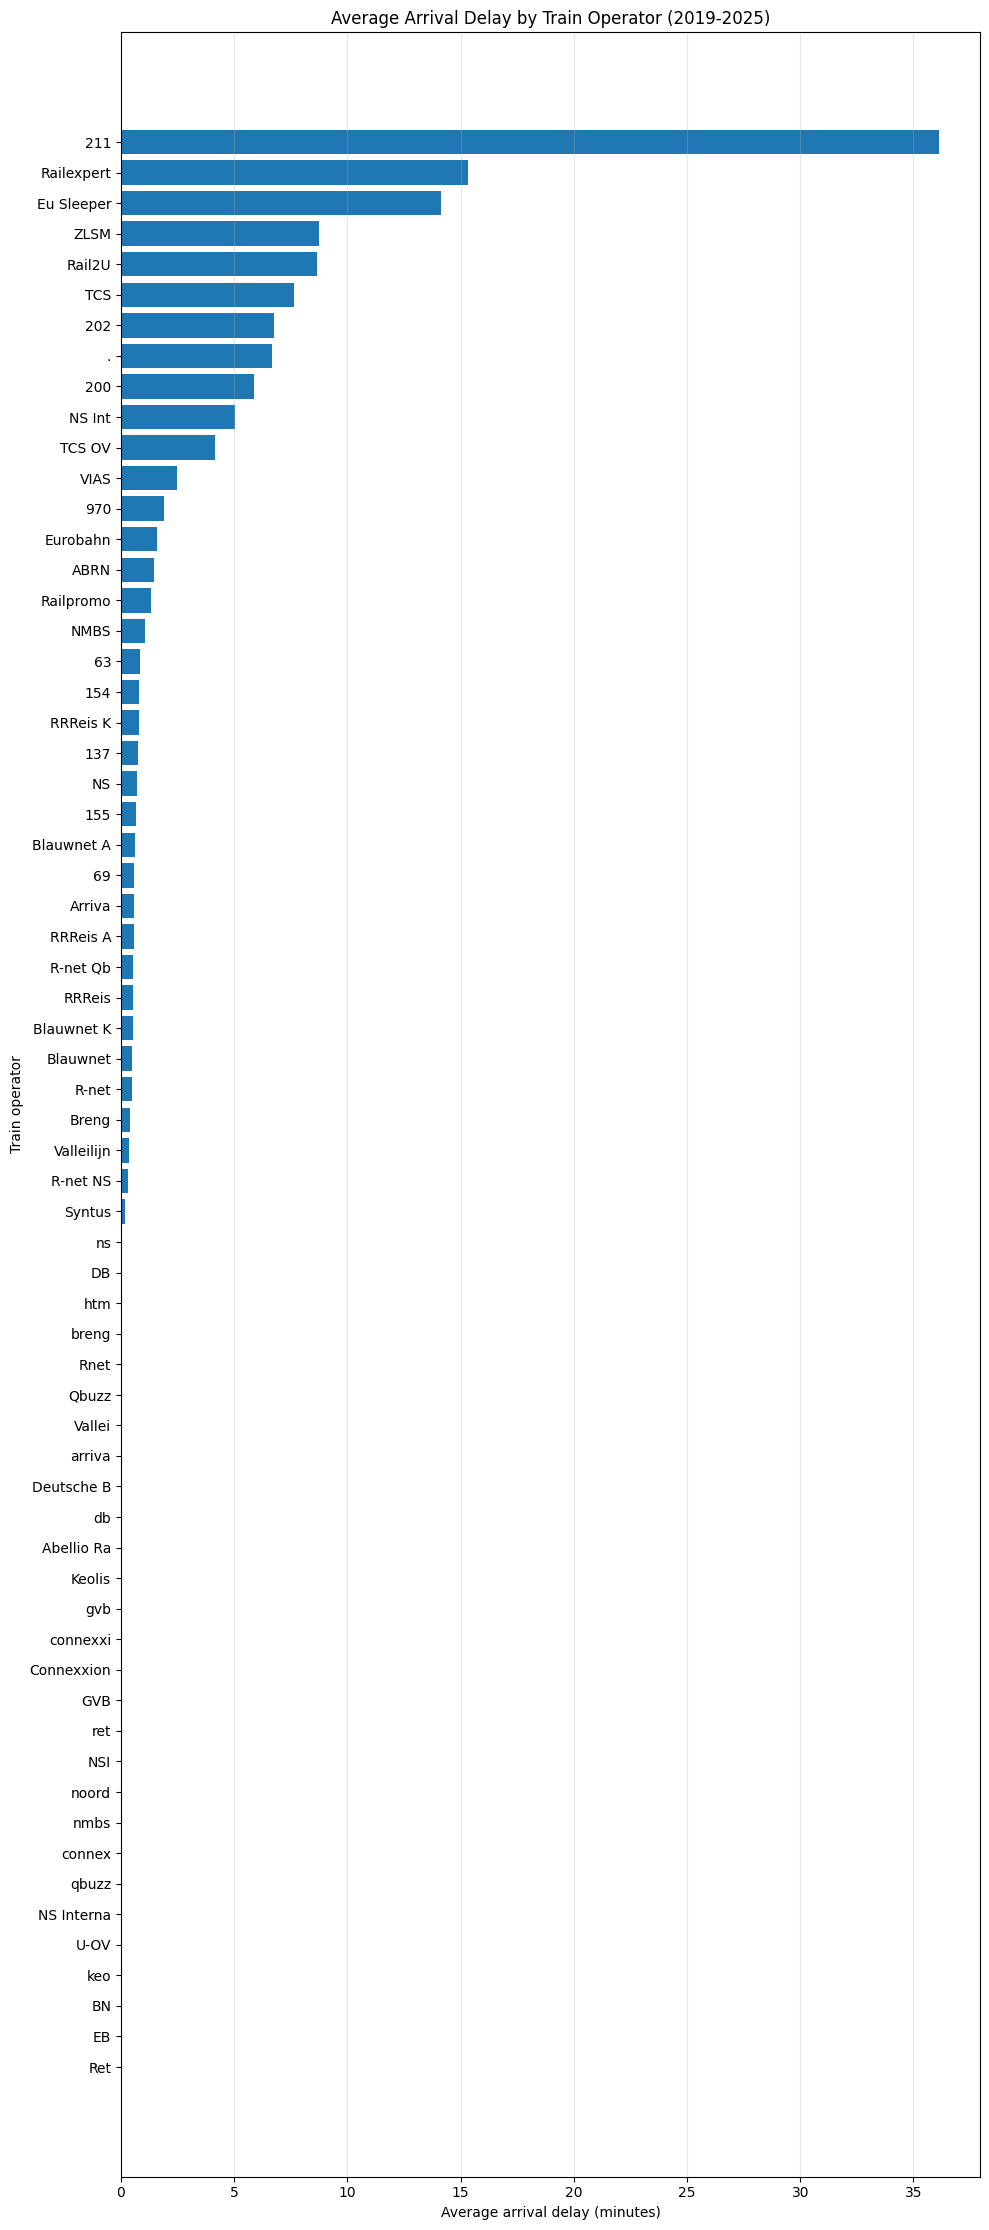

In [7]:
# 7. Compare average arrival delay by train operator.
import matplotlib.pyplot as plt

average_delay_by_company = db.sql("""
    SELECT "Service:Company" AS operator,
           AVG("Stop:Arrival delay") AS average_arrival_delay_minutes
    FROM services
    WHERE "Stop:Arrival delay" IS NOT NULL
      AND "Service:Company" IS NOT NULL
    GROUP BY "Service:Company"
    ORDER BY average_arrival_delay_minutes
""").df()

fig, ax = plt.subplots(figsize=(10, max(5, len(average_delay_by_company) * 0.35)))
ax.barh(average_delay_by_company["operator"],
        average_delay_by_company["average_arrival_delay_minutes"])
ax.set_title("Average Arrival Delay by Train Operator (2019-2025)")
ax.set_xlabel("Average arrival delay (minutes)")
ax.set_ylabel("Train operator")
ax.grid(axis="x", alpha=0.3)
fig.tight_layout()
plt.show()

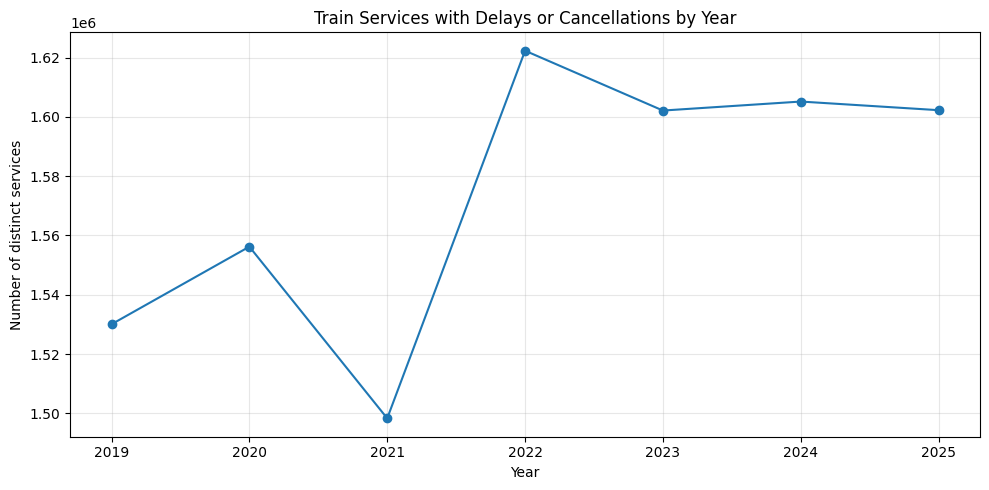

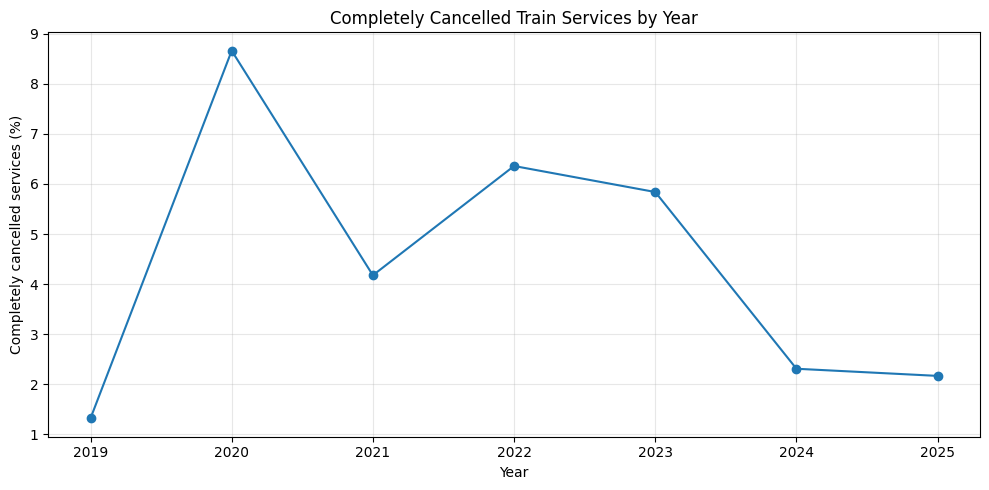

,year,disrupted_services
0,2019,1530040
1,2020,1556217
2,2021,1498298
3,2022,1622330
4,2023,1602143
5,2024,1605179
6,2025,1602266


,year,total_services,completely_cancelled_services,fraction_completely_cancelled
0,2019,2369241,31303,0.013212
1,2020,2453753,212447,0.086580
2,2021,2352676,98253,0.041762
3,2022,2453625,155981,0.063572
4,2023,2323100,135619,0.058378
5,2024,2395636,55360,0.023109
6,2025,2402665,52098,0.021683


In [8]:
# 8. Distinct services with a delay or cancellation by year.
annual_disrupted_services = db.sql("""
    SELECT YEAR("Service:Date") AS year,
           COUNT(DISTINCT "Service:RDT-ID") FILTER (
               WHERE COALESCE("Service:Maximum delay", 0) > 0
                  OR COALESCE("Service:Partly cancelled", FALSE)
                  OR COALESCE("Service:Completely cancelled", FALSE)
           ) AS disrupted_services
    FROM services
    GROUP BY year
    ORDER BY year
""").df()

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(annual_disrupted_services["year"],
        annual_disrupted_services["disrupted_services"], marker="o")
ax.set_title("Train Services with Delays or Cancellations by Year")
ax.set_xlabel("Year")
ax.set_ylabel("Number of distinct services")
ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()

# 9. Fraction of distinct services completely cancelled by year.
annual_cancellation_fraction = db.sql("""
    SELECT YEAR("Service:Date") AS year,
           COUNT(DISTINCT "Service:RDT-ID") AS total_services,
           COUNT(DISTINCT "Service:RDT-ID") FILTER (
               WHERE COALESCE("Service:Completely cancelled", FALSE)
           ) AS completely_cancelled_services,
           COUNT(DISTINCT "Service:RDT-ID") FILTER (
               WHERE COALESCE("Service:Completely cancelled", FALSE)
           )::DOUBLE / NULLIF(COUNT(DISTINCT "Service:RDT-ID"), 0)
             AS fraction_completely_cancelled
    FROM services
    GROUP BY year
    ORDER BY year
""").df()

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(annual_cancellation_fraction["year"],
        annual_cancellation_fraction["fraction_completely_cancelled"] * 100,
        marker="o")
ax.set_title("Completely Cancelled Train Services by Year")
ax.set_xlabel("Year")
ax.set_ylabel("Completely cancelled services (%)")
ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()

display(annual_disrupted_services)
display(annual_cancellation_fraction)

## Step 8: Calculate distances traveled between consecutive stations


In [9]:
db.execute("""
    CREATE OR REPLACE TABLE station_connections AS
    WITH ordered_stops AS (
        SELECT "Service:RDT-ID" AS service_id,
               "Stop:Station code" AS start_station_code,
               LEAD("Stop:Station code") OVER (
                   PARTITION BY "Service:RDT-ID"
                   ORDER BY "Stop:Departure time" ASC NULLS LAST,
                            "Stop:Arrival time" ASC NULLS LAST
               ) AS end_station_code
        FROM services
        WHERE "Stop:Station code" IS NOT NULL
    ),
    unique_service_connections AS (
        SELECT DISTINCT service_id, start_station_code, end_station_code
        FROM ordered_stops
        WHERE end_station_code IS NOT NULL
          AND start_station_code <> end_station_code
    )
    SELECT c.service_id AS "Service:RDT-ID",
           c.start_station_code,
           c.end_station_code,
           d.distance
    FROM unique_service_connections c
    LEFT JOIN distances_long d
      ON d.Station = c.start_station_code
     AND d.other_station = c.end_station_code
""")

connection_summary = db.sql("""
    SELECT COUNT(*) AS service_station_pairs,
           COUNT(distance) AS pairs_with_known_distance,
           COUNT(*) - COUNT(distance) AS pairs_without_known_distance
    FROM station_connections
""").df()
display(connection_summary)
display(db.sql("SELECT * FROM station_connections LIMIT 10").df())

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,service_station_pairs,pairs_with_known_distance,pairs_without_known_distance
0,135425628,127380518,8045110


,Service:RDT-ID,start_station_code,end_station_code,distance
0,742644,DT,RTD,14
1,745487,KLP,ED,7
2,746906,BP,LW,24
3,749221,KMR,SOG,2
4,750546,HWZB,ASS,7
5,751499,LEDN,LDL,1
6,755194,HLM,HAD,4
7,760203,VNDC,VNDW,1
8,779255,HWD,AMRN,6
9,779802,BDM,SWD,4


In [10]:
# 8.3. Longest distance between two consecutive stations traveled by a service.
longest_station_connection = db.sql("""
    SELECT c."Service:RDT-ID",
           c.start_station_code,
           s1.name_long AS start_station,
           c.end_station_code,
           s2.name_long AS end_station,
           c.distance AS distance_km
    FROM station_connections c
    LEFT JOIN stations s1 ON c.start_station_code = s1.code
    LEFT JOIN stations s2 ON c.end_station_code = s2.code
    WHERE c.distance IS NOT NULL
    ORDER BY c.distance DESC
    LIMIT 1
""").df()
display(longest_station_connection)

,Service:RDT-ID,start_station_code,start_station,end_station_code,end_station,distance_km
0,7123701,VS,Vlissingen,STV,Stavoren,421


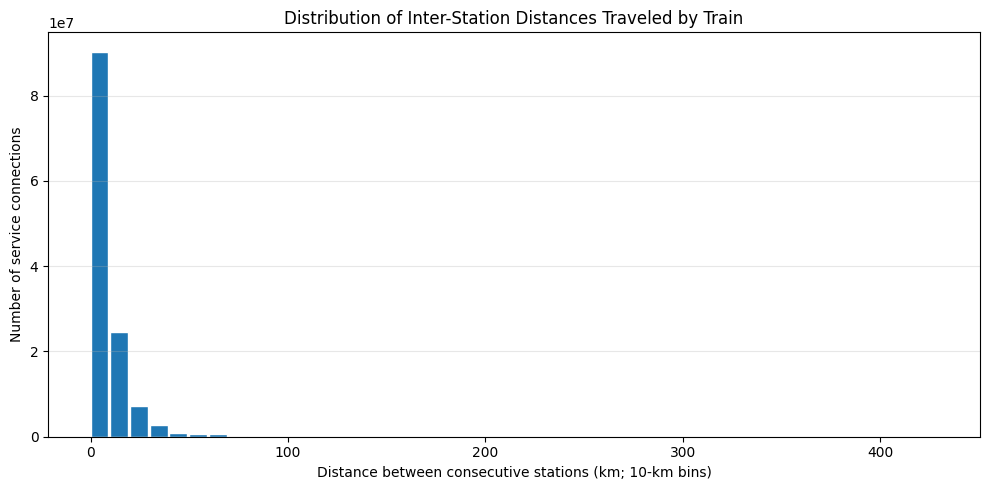

,distance_bin_start_km,train_connection_count
0,0,90353615
1,10,24648891
2,20,7223043
3,30,2814473
4,40,826352
5,50,629298
6,60,595529
7,70,212726
8,80,22512
9,90,7396


In [11]:
# 8.4. Aggregate distances into 10-km bins in DuckDB, then plot the histogram.
distance_histogram = db.sql("""
    SELECT (FLOOR(distance / 10.0) * 10)::INTEGER AS distance_bin_start_km,
           COUNT(*) AS train_connection_count
    FROM station_connections
    WHERE distance IS NOT NULL
    GROUP BY distance_bin_start_km
    ORDER BY distance_bin_start_km
""").df()

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(distance_histogram["distance_bin_start_km"],
       distance_histogram["train_connection_count"],
       width=9, align="edge", edgecolor="white")
ax.set_title("Distribution of Inter-Station Distances Traveled by Train")
ax.set_xlabel("Distance between consecutive stations (km; 10-km bins)")
ax.set_ylabel("Number of service connections")
ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
plt.show()

display(distance_histogram)

This had more work to do than specified in LAB_INSTRUCTION.md, but I had much less 'weird problems' compared to lab work. I learnt quite a few tricks, like NULLIF, UNPIVOT, etc.